# Más allá: la UF como moneda propia y una prueba que detecta un supuesto de comportamiento cambiado ante un incumplimiento de límite

**Pregunta:** ¿tratar la UF como una moneda propia cambia las medidas del Anexo 1 de un banco con balance en pesos y UF en más que el redondeo de un método (BS-7), y la prueba de exceso distingue un parámetro de comportamiento cambiado mientras se incumple un límite de uno que se mantiene fijo o que cambia sin exceso (BS-8)?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 01 a 07 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar las dos afirmaciones de este tema, BS-7 (la UF como moneda propia en IRRBB) y BS-8 (una prueba que marca un supuesto de comportamiento cambiado ante un exceso de límite), la evidencia versionada de cada una, la práctica que cada una supera y el límite de cada afirmación;
- mostrar, con el motor, qué perdería un tratamiento de la UF como una sola moneda frente al Anexo 1 (tamaños, piso, compensación y cargo);
- correr la prueba de exceso sobre historias controladas y sobre los parámetros versionados, y decir qué discrimina y qué no;
- decir qué hace un validador con un resultado rojo de esta prueba.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos casos alimentan las dos afirmaciones.

- **BS-7** lee el caso C15, el Banco Andino **sintético** sobre un balance en pesos y UF al 2026-09-03, en cuatro de sus seis variantes: `short-uf`, `long-uf`, `offset-on-off` y `floors-active`. Los agregados del balance están calibrados a las cifras del sistema de la CMF de agosto de 2026 (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, estadísticas públicas, clase de licencia `mirror-allowed`); las curvas son los rendimientos reales del Banco Central de Chile (cuadro F022 de la BDE, `mirror-allowed`). El dinero está en millones de CLP.
- **BS-8** lee el caso C14, el banco que quebró en marzo de 2023, en las fechas de valoración 2021-Q4, 2022-Q2 y 2022-Q4: los reportes de condición de la FDIC (https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**: la proporción y el plazo de los depósitos estables los declara Contraste, y el plazo de la cartera replicante se ajusta con el historial de reportes. El dinero está en miles de USD.

Un delta EVE o delta NII positivo es una pérdida en ambos.

- **Archivos que se leen:** `data/derived/C15/short-uf.json`, `long-uf.json`, `offset-on-off.json` y `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `thresholds`), `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.nmd_segments`, `scenarios`) y `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `nmd_parameter_changes`).

La celda siguiente carga los archivos y lista las variantes y las fechas de valoración.

In [2]:
# Cargar las cuatro variantes de C15, las tres fechas de valoración de C14 y el documento de modelos de C14
ROOT = Path("../../..").resolve()
c15, c14 = ROOT / "data" / "derived" / "C15", ROOT / "data" / "derived" / "C14"
names = ("short-uf", "long-uf", "offset-on-off", "floors-active")
variants = {v: json.loads((c15 / f"{v}.json").read_text(encoding="utf-8")) for v in names}
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((c14 / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((c14 / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {True: "sí", False: "no"}
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
print("C15:", list(variants))
print("C14:", [d["outputs"]["valuation_date"] for d in docs.values()])

C15: ['short-uf', 'long-uf', 'offset-on-off', 'floors-active']
C14: ['2021-12-31', '2022-06-30', '2022-12-31']


## Método

El notebook enuncia cada afirmación, muestra la evidencia de los archivos versionados con el motor, y muestra un control o un contrafactual que hace comprobable la afirmación: para BS-7 el costo de no tratar la UF como una moneda, para BS-8 historiales donde la prueba debe dar verde y donde debe dar rojo. Cada afirmación termina con su límite. Las afirmaciones y su evidencia están enunciadas en la sección `## Beyond the state of the art` del SDD; el notebook no afirma más de lo que afirma el SDD.

- **BS-7.** El riesgo de reajustabilidad del Anexo 1 de la RAN 21-13 como una moneda separada (la UR) con sus propios choques, piso, el cargo por reajustabilidad (2,5 por ciento de la posición neta en UF en valor absoluto) y la compensación de 50 por ciento del delta en pesos contra el delta UR. Evidencia: `data/derived/C15/long-uf.json`, `floors-active.json`, `offset-on-off.json`.
- **BS-8.** La prueba `irrbb.behavioural_change_at_breach`, que convierte un hallazgo de la revisión de la Reserva Federal sobre el banco quebrado en una prueba de validación. Evidencia: los parámetros versionados de `data/derived/C14/models-svb-2021-2022.json` y las marcas de incumplimiento de las tres fechas.

## Estado del arte

**Para BS-7.** El estándar de Basilea tiene 21 monedas en su tabla de choques y una regla para agregarlas; no tiene una unidad como la UF, una unidad de cuenta reajustable cuyo valor en moneda local sigue a la inflación, y ninguna moneda de la jurisdicción local que falte en la tabla recibe un tamaño (SRP31.90, Tabla 2; BCBS d578, https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf). El Anexo 1 del capítulo 21-13 del regulador chileno (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf) llena esa brecha con la UR. La investigación encontró el enfoque chileno descrito como "un diferenciador genuino" (dossier 03, F.2) y no encontró una implementación pública del Anexo; es un hallazgo de la búsqueda del dossier y sigue **NO VERIFICADO** más allá de ella. La afirmación es regional, no global.

**Para BS-8.** La revisión de la Reserva Federal sobre Silicon Valley Bank enuncia la práctica como un hallazgo: el banco "había incumplido sus límites de riesgo de tasa de largo plazo de forma intermitente desde 2017" y "en abril de 2022 ... hizo supuestos de modelación contraintuitivos sobre la duración de los depósitos para enfrentar el incumplimiento del límite en vez de gestionar el riesgo real" (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf; dossier 05, D.7). La investigación propone la prueba ("una prueba de validación de Contraste debería entonces marcar todo cambio en los parámetros de comportamiento de los depósitos que coincida con un incumplimiento de límite") y no cita ninguna herramienta que la implemente.

La primera celda de abajo muestra el primer hecho de BS-7 con el motor: la tabla de Basilea no tiene entrada para el peso ni para la UF, y el motor rechaza un tamaño para ellos en vez de inventarlo.

In [3]:
# La tabla de Basilea no tiene el peso ni la UF: el motor rechaza un tamaño; la tabla chilena tiene ambos
for calibration in ("2016", "2024"):
    table = shocks.shock_table(calibration)
    has = [("no", "sí")[c in table] for c in ("CLP", "CLF")]
    print(calibration, "| monedas:", len(table), "| CLP:", has[0], "| CLF:", has[1])
for currency in ("CLP", "CLF"):
    try:
        shocks.shock_size(currency, "2024")
    except ValueError as error:
        print(currency, "el motor rechaza un tamaño:", type(error).__name__)
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency} cmf-annex1: {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} pb | origen {z.origin}")

2016 | monedas: 21 | CLP: no | CLF: no
2024 | monedas: 21 | CLP: no | CLF: no
CLP el motor rechaza un tamaño: ValueError
CLF el motor rechaza un tamaño: ValueError
CLP cmf-annex1: 300/400/200 pb | origen cmf-annex1
CLF cmf-annex1: 200/250/150 pb | origen cmf-annex1


## Más allá del estado del arte

### BS-7: la UF como moneda propia

**Lo que agrega la afirmación.** El Anexo 1 del capítulo 21-13 trata el riesgo de reajustabilidad como una moneda separada con sus propios choques, su propio piso, el cargo por reajustabilidad y la compensación de 50 por ciento; el motor lo implementa, y las variantes versionadas de C15 se recalculan desde él. La primera celda muestra la separación en los documentos versionados: los tamaños y el piso de cada moneda y la curva en que se descuenta cada una. La segunda muestra por qué el piso debe ser el propio de la moneda: la curva UR es una curva de tasas reales, de 1,2 a 2,8 por ciento, y un choque a la baja de 200 pb empuja su extremo corto bajo cero, donde el piso del peso de 0 por ciento actuaría en nueve bandas y el piso UR de -2 por ciento en ninguna.

tamaños EVE (par/corto/largo) | tamaño NII | piso | tasa banda 1 | tasa banda 19
CLP  300/400/200 | 300 | 0.00
    0.04499 | 0.05911
UR   200/250/150 | 300 | -0.02
    0.01205 | 0.02839


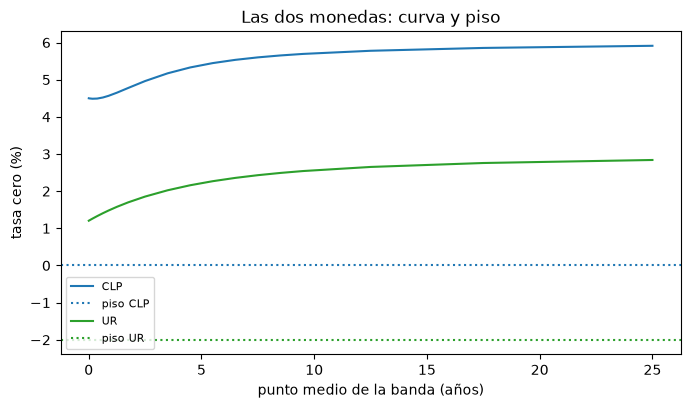

In [4]:
# Los tamaños, el piso y la curva de cada moneda en los documentos versionados, y el tamaño del motor para cada una
out = variants["short-uf"]["outputs"]
rates = {"CLP": np.array(out["curves"]["clp"]["zero_rates_at_midpoints"])}
rates["UR"] = np.array(out["curves"]["ur"]["zero_rates_at_midpoints"])
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
print("tamaños EVE (par/corto/largo) | tamaño NII | piso | tasa banda 1 | tasa banda 19")
for committed in out["eve_shock_sizes"]:
    leg = "CLP" if committed["currency"] == "CLP" else "UR"
    nii = next(x["parallel_bp"] for x in out["nii_shock_sizes"] if x["currency"] == committed["currency"])
    z = shocks.shock_size(committed["currency"], "cmf-annex1")
    print(f"{leg:4s} {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} | {nii:.0f} | {floors[leg]:.2f}")
    print(f"    {rates[leg][0]:.5f} | {rates[leg][18]:.5f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for leg, colour in (("CLP", "tab:blue"), ("UR", "tab:green")):
    ax.plot(MID, rates[leg] * 100, color=colour, label=leg)
    ax.axhline(floors[leg] * 100, color=colour, linestyle=":", label="piso " + leg)
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("tasa cero (%)")
ax.set_title("Las dos monedas: curva y piso")
ax.legend(fontsize=8)
plt.show()

Las dos líneas continuas son las curvas en que se descuenta cada moneda, la curva en pesos entre cerca de 4,5 y 5,9 por ciento y la curva real en UF entre 1,2 y 2,8 por ciento, y las líneas punteadas son los pisos de cada moneda: 0 por ciento para el peso y -2 por ciento para la UR. Los tamaños impresos arriba también difieren, 300/400/200 pb para el peso y 200/250/150 pb para la UR en el EVE, y los mismos 300 pb en el NII. Todo lo que el Anexo 1 separa se ve aquí: una curva, un conjunto de tamaños y un piso por moneda, que un tratamiento de una sola moneda reemplazaría por los del peso. La figura muestra los insumos de la afirmación; el paso siguiente muestra qué hacen con un resultado.

Ahora el piso. La celda siguiente aplica una caída de 200 pb a la curva UR de la primera variante con el piso del peso y luego con el piso UR, y lista las bandas donde cada piso actúa.

piso en pesos (0)            bandas donde actúa: [1, 2, 3, 4, 5, 6, 7, 8, 9]
piso UR (-2 por ciento)      bandas donde actúa: []
tasa más baja de la curva UR tras -200 pb, antes del piso: -0.00795


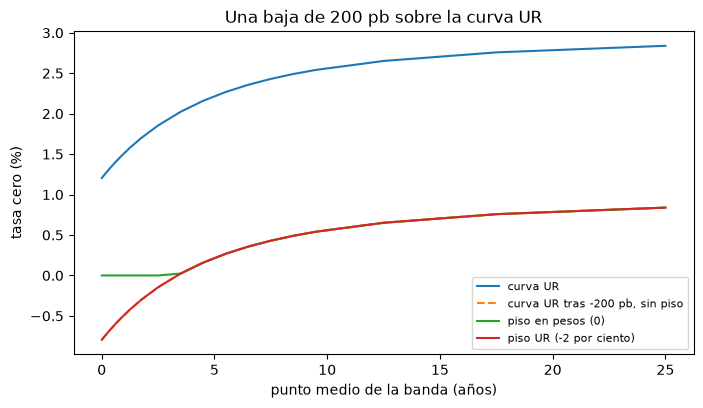

In [5]:
# Aplicar una baja de 200 pb a la curva UR con el piso en pesos y con el piso UR y ver dónde actúa cada uno
shape = np.full(19, -200.0)
raw = shocks.apply_floor(rates["UR"], shape, None)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(MID, rates["UR"] * 100, label="curva UR")
ax.plot(MID, raw * 100, linestyle="--", label="curva UR tras -200 pb, sin piso")
for label, floor in (("piso en pesos (0)", 0.0), ("piso UR (-2 por ciento)", -0.02)):
    floored = shocks.apply_floor(rates["UR"], shape, floor)
    bound = [int(k) + 1 for k in np.flatnonzero(np.abs(floored - raw) > 1e-12)]
    print(f"{label:28s} bandas donde actúa: {bound}")
    ax.plot(MID, floored * 100, label=label)
print("tasa más baja de la curva UR tras -200 pb, antes del piso:", round(float(raw.min()), 5))
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("tasa cero (%)")
ax.set_title("Una baja de 200 pb sobre la curva UR")
ax.legend(fontsize=8)
plt.show()

La línea de trazos es la curva real tras una baja de 200 pb, con su extremo corto en -0,795 por ciento. El piso en pesos devuelve las nueve primeras bandas a cero, la línea que queda sobre el eje, y así cambiaría una curva de tasas reales que no tiene razón para ser no negativa; el piso UR de -2 por ciento queda bajo toda la curva con choque y no actúa en ninguna banda. Por eso el piso tiene que ser el propio de la moneda: el piso en pesos aplicado a la UF fabricaría una pérdida en una moneda cuyas tasas eran bajas pero legítimamente positivas al comienzo y negativas tras el choque. La figura muestra un choque sobre una curva en una fecha y no muestra que alguno de los pisos actúe en las variantes versionadas, lo que el límite de BS-7 más abajo dice con claridad.

**La compensación y el cargo.** La regla de compensación da la mitad del crédito al tramo con ganancia cuando los dos deltas tienen signos opuestos. La variante `offset-on-off` guarda el par con y sin la compensación, y las mismas funciones del motor dan las medidas del Anexo de ambas formas para las cuatro variantes. El cargo se suma una vez al delta NII sea cual sea la compensación. La celda siguiente imprime ambas medidas con y sin la compensación, la proporción del delta NII que es el cargo, y la mayor cercanía de alguna tasa posterior al choque a su piso, y dibuja el efecto de la compensación.

short-uf       ΔEVE     79,643     79,643
    ΔNII     11,067     14,597
    cargo / ΔNII 0.5586 | piso más cercano (pb) 20.48
long-uf        ΔEVE     93,816     94,721
    ΔNII     11,213     14,597
    cargo / ΔNII 0.5513 | piso más cercano (pb) 20.48
offset-on-off  ΔEVE     81,173     94,721
    ΔNII     11,016     14,597
    cargo / ΔNII 0.5612 | piso más cercano (pb) 20.48
floors-active  ΔEVE     60,764     60,764
    ΔNII      6,606      7,528
    cargo / ΔNII 0.1560 | piso más cercano (pb) 20.48


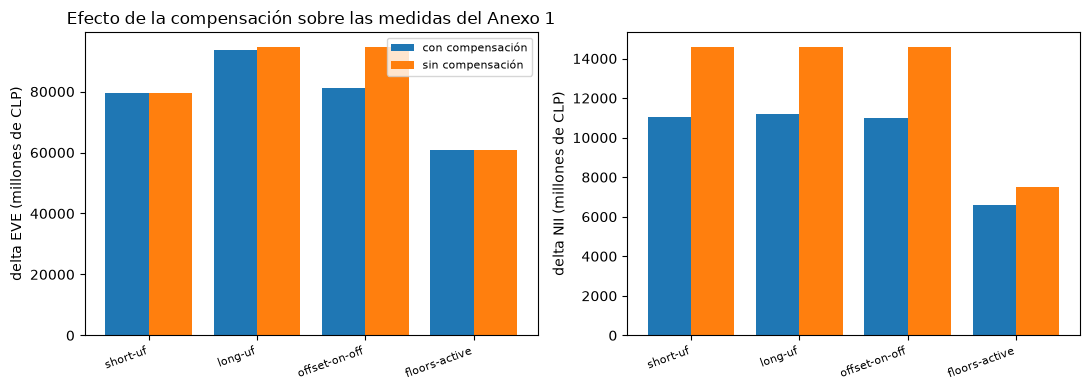

In [6]:
# Las medidas del Anexo con y sin compensación, el cargo como proporción del delta NII y el piso más cercano
annex = {}
for v, d in variants.items():
    o = d["outputs"]
    d_clp, d_ur = (np.array([r["pair"][k] for r in o["eve"]["rows"]]) for k in ("delta_clp", "delta_ur"))
    n_clp, n_ur = (np.array([r["pair"][k] for r in o["nii"]["rows"]]) for k in ("delta_clp", "delta_ur"))
    eve_on, eve_off = (eve_nii.annex1_delta_eve(d_clp, d_ur, flag) for flag in (True, False))
    pn = o["indexation_charge"]["pn_ur"]
    nii_on, nii_off = (eve_nii.annex1_delta_nii(n_clp, n_ur, pn, flag) for flag in (True, False))
    closest = min(x["distance_bp"] for x in o["floors"]["distances"])
    annex[v] = (eve_on.delta_eve, nii_on.delta_nii, eve_off.delta_eve, nii_off.delta_nii)
    print(f"{v:14s} ΔEVE {eve_on.delta_eve:10,.0f} {eve_off.delta_eve:10,.0f}")
    print(f"    ΔNII {nii_on.delta_nii:10,.0f} {nii_off.delta_nii:10,.0f}")
    print(f"    cargo / ΔNII {nii_on.indexation_charge / nii_on.delta_nii:.4f} | piso más cercano (pb) {closest:.2f}")
x = np.arange(len(annex))
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
panels = ((left, (0, 2), "delta EVE (millones de CLP)"), (right, (1, 3), "delta NII (millones de CLP)"))
for ax, (k_on, k_off), ylabel in panels:
    ax.bar(x - 0.2, [annex[v][k_on] for v in annex], 0.4, label="con compensación")
    ax.bar(x + 0.2, [annex[v][k_off] for v in annex], 0.4, label="sin compensación")
    ax.set_xticks(x, list(annex), rotation=20, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
left.set_title("Efecto de la compensación sobre las medidas del Anexo 1")
left.legend(fontsize=8)
fig.tight_layout()
plt.show()

La compensación actúa sobre todo en el NII. En la variante short-uf baja el delta NII de 14.597 a 11.067, 24 por ciento, y en la variante offset-on-off baja el delta EVE de 94.721 a 81.173, 14 por ciento; en la variante short-uf no cambia el delta EVE porque el peor choque tiene a ambos tramos perdiendo. El cargo es 55,9, 55,1 y 56,1 por ciento del delta NII en las tres variantes con una posición neta en UF de 30 por ciento del Tier 1, y 15,6 por ciento en la variante con 5 por ciento. La mayor cercanía de alguna tasa con choque a su piso es 20,48 pb en las cuatro. La figura muestra el efecto de una regla sobre cuatro variantes sintéticas, no una afirmación sobre ningún banco real.

**El contrafactual: lo que pierde un tratamiento de una sola moneda.** Sin la UR, un banco pondría sus flujos en UF, convertidos a pesos, con los flujos en pesos, los descontaría todos con la curva en pesos, los sometería a los choques con los tamaños del peso y el piso en cero, y no sumaría ningún cargo: una sola moneda. La celda hace exactamente eso con el motor para las cuatro variantes, usando los flujos netos versionados de cada tramo, y compara las dos medidas y las razones al Tier 1. Es un contrafactual, no un método rival: muestra lo que se pierde cuando la UF no es una moneda propia. La diferencia tiene cuatro partes que actúan juntas, la curva (nominal en vez de real), los tamaños (los del peso para los flujos en UF), la compensación total de los tramos dentro de una sola suma, y el cargo ausente.

In [7]:
# Medidas del Anexo 1 frente a una sola moneda con los mismos flujos: curva, tamaños y piso en pesos, sin cargo
peso = shocks.shock_size("CLP", "cmf-annex1")
single = {}
for v, d in variants.items():
    o = d["outputs"]
    uf = o["ur_currency"]["uf_value"]
    rows = {leg["leg"]: [r for item in leg["items"] for r in item["cash_flows"]] for leg in o["legs"]}
    vec = {k: np.bincount([r["bucket"] - 1 for r in rs], [r["amount"] for r in rs], 19) for k, rs in rows.items()}
    total = vec["CLP"] + uf * vec["UR"]
    r_peso = np.array(o["curves"]["clp"]["zero_rates_at_midpoints"])
    loss_eve = []
    for row in o["eve"]["rows"]:
        net = np.array(row["clp"]["net_cash_flows"]) + np.array(row["ur"]["net_cash_flows"])
        shape = shocks.shock_curve(row["shock"], peso.parallel_bp, peso.short_bp, peso.long_bp, MID)
        shocked = shocks.apply_floor(r_peso, shape, 0.0)
        loss_eve.append(eve_nii.delta_eve(total, net, r_peso, shocked, MID))
    flat = [shocks.apply_floor(r_peso, np.full(19, bp), 0.0) for bp in (300.0, -300.0)]
    loss_nii = [eve_nii.delta_nii(total, r_peso, shocked, MID) for shocked in flat]
    single[v] = (max(0.0, max(loss_eve)), max(0.0, max(loss_nii)))
    print(f"{v:14s} ΔEVE Anexo 1 {annex[v][0]:10,.0f} | una moneda {single[v][0]:10,.0f}")
    print(f"    ΔNII Anexo 1 {annex[v][1]:10,.0f} | una moneda {single[v][1]:10,.0f}")

short-uf       ΔEVE Anexo 1     79,643 | una moneda     64,213
    ΔNII Anexo 1     11,067 | una moneda      1,356
long-uf        ΔEVE Anexo 1     93,816 | una moneda     84,710
    ΔNII Anexo 1     11,213 | una moneda      1,648
offset-on-off  ΔEVE Anexo 1     81,173 | una moneda     59,422
    ΔNII Anexo 1     11,016 | una moneda      1,254
floors-active  ΔEVE Anexo 1     60,764 | una moneda     49,837
    ΔNII Anexo 1      6,606 | una moneda      4,653


La celda siguiente dibuja las cuatro medidas de cada variante como proporción del Tier 1, con la línea de 15 por ciento del EVE y la de 5 por ciento del NII.

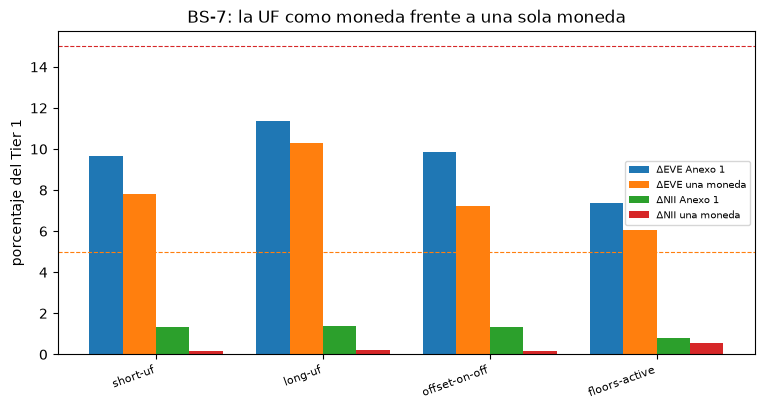

In [8]:
# Dibujar las medidas del Anexo 1 y el contrafactual de una sola moneda como proporción del Tier 1
tier = {v: d["outputs"]["thresholds"]["tier1"] for v, d in variants.items()}
series = []
specs = [("ΔEVE Anexo 1", annex, 0), ("ΔEVE una moneda", single, 0)]
specs += [("ΔNII Anexo 1", annex, 1), ("ΔNII una moneda", single, 1)]
for label, source, k in specs:
    series.append((label, [source[v][k] / tier[v] for v in variants]))
x = np.arange(len(variants))
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, (label, values) in enumerate(series):
    ax.bar(x + (k - 1.5) * 0.2, [100 * value for value in values], 0.2, label=label)
ax.axhline(15, color="tab:red", linestyle="--", linewidth=0.8)
ax.axhline(5, color="tab:orange", linestyle="--", linewidth=0.8)
ax.set_xticks(x, list(variants), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("porcentaje del Tier 1")
ax.set_title("BS-7: la UF como moneda frente a una sola moneda")
ax.legend(fontsize=7)
plt.show()

Tratar los flujos en UF como pesos da un delta NII de 1.356, 1.648 y 1.254 para las variantes short-uf, long-uf y offset-on-off frente a los valores del Anexo 1 de 11.067, 11.213 y 11.016: entre 6,8 y 8,8 veces menor, porque la suma de una sola moneda no tiene cargo y deja que los tramos se neteen por completo. El delta EVE es 64.213, 84.710 y 59.422 frente a 79.643, 93.816 y 81.173: entre 10 y 27 por ciento menor. En la variante floors-active, con una posición neta en UF de 5 por ciento del Tier 1, la brecha es menor, 4.653 frente a 6.606 para el NII. En estas cuatro variantes ninguna razón cruza su línea con ninguno de los dos tratamientos, así que la afirmación no es que un banco aprobaría o fallaría distinto sino que la medida que define el regulador no es la que da un cálculo de una sola moneda.

**El límite de BS-7.** La evidencia muestra que el motor implementa el Anexo 1 como una moneda separada y que las variantes versionadas se recalculan desde él. No muestra que el Anexo se aplique como lo aplica la CMF: no hay una segunda implementación con la cual reconciliar, y la búsqueda del dossier no encontró ninguna (NO VERIFICADO más allá de esa búsqueda). Los pisos están implementados y probados, pero nunca actúan sobre las curvas versionadas, siendo el más cercano uno a 20,48 pb, así que su efecto sobre un número no queda demostrado con estos datos. El banco es sintético. Y la afirmación es regional: el estándar no tiene una unidad como la UF, y solo el Anexo chileno la necesita aquí.

### BS-8: una prueba que marca un supuesto de comportamiento cambiado ante un incumplimiento de límite

**Lo que agrega la afirmación.** `irrbb.behavioural_change_at_breach` recibe la serie de un parámetro de comportamiento, las fechas y una marca de incumplimiento por fecha, y cuenta las fechas en que el parámetro cambió y la marca es verdadera. Es roja con uno o más, verde con ninguno, y `not_evaluated` con menos de dos fechas. La primera celda muestra que la prueba discrimina, sobre cinco historiales construidos cuya respuesta es conocida: un parámetro mantenido fijo durante un incumplimiento, un parámetro que cambia sin incumplimiento, un parámetro cambiado ante un incumplimiento, un parámetro cambiado antes del incumplimiento pero no en él, y una sola fecha. Son números construidos que ejercitan la regla, no datos de ningún banco.

fija durante un exceso       [4.0, 4.0, 4.0] ['sí', 'sí', 'sí']
    verde | fechas marcadas: []
cambia, sin exceso           [4.0, 4.5, 5.0] ['no', 'no', 'no']
    verde | fechas marcadas: []
cambia en un exceso          [4.0, 4.0, 4.5] ['no', 'no', 'sí']
    rojo | fechas marcadas: ['2022-12-31']
cambia antes del exceso      [4.0, 4.5, 4.5] ['no', 'no', 'sí']
    verde | fechas marcadas: []
una sola fecha               [4.0] ['sí']
    no evaluado | fechas marcadas: []


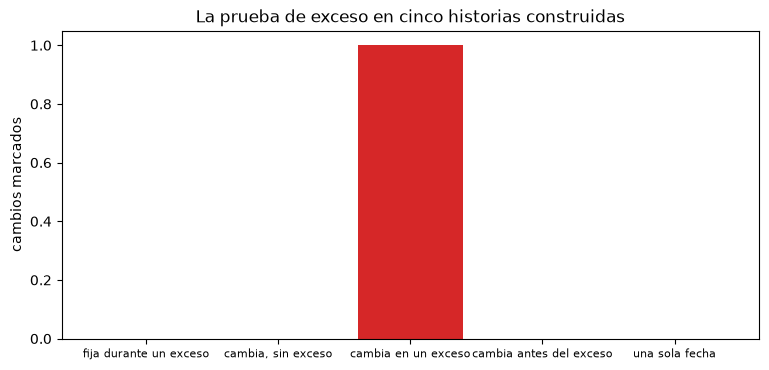

In [9]:
# Cinco historias construidas con respuesta conocida: fija, cambia sin exceso, cambia en o antes de un exceso
days = np.array(["2021-12-31", "2022-06-30", "2022-12-31"], dtype="datetime64[D]")
cases = [
    ("fija durante un exceso", [4.0, 4.0, 4.0], [True, True, True], days),
    ("cambia, sin exceso", [4.0, 4.5, 5.0], [False, False, False], days),
    ("cambia en un exceso", [4.0, 4.0, 4.5], [False, False, True], days),
    ("cambia antes del exceso", [4.0, 4.5, 4.5], [False, False, True], days),
    ("una sola fecha", [4.0], [True], days[:1]),
]
results = []
for label, values, flags, when in cases:
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), when, np.array(flags, dtype=bool))
    results.append(run)
    print(f"{label:28s} {values} {[NAME[f] for f in flags]}")
    print(f"    {LIGHT[run.light.value]} | fechas marcadas: {run.extras.get('flagged_dates', [])}")
tint = {"green": "tab:green", "red": "tab:red", "not_evaluated": "lightgrey"}
fig, ax = plt.subplots(figsize=(9, 4))
counts = [np.nan_to_num(run.statistic) for run in results]
ax.bar([c[0] for c in cases], counts, color=[tint[run.light.value] for run in results])
ax.set_ylabel("cambios marcados")
ax.set_title("La prueba de exceso en cinco historias construidas")
ax.tick_params(axis="x", labelsize=8)
plt.show()

Solo la tercera historia es roja, el parámetro que pasa de 4,0 a 4,5 en la fecha en que se incumple el límite, y la prueba nombra esa fecha, 2022-12-31. El parámetro fijo durante un exceso es verde, así que un exceso solo no la dispara; el parámetro que cambia sin exceso es verde, así que un cambio solo tampoco; y el parámetro que cambió antes del exceso y luego se mantuvo es verde, porque el cambio no coincidió con él. Una sola fecha no se puede comparar y la prueba lo dice en vez de devolver un número. Son números construidos que ejercitan la regla: muestran que la prueba discrimina, no que alguien haya hecho lo que hace la tercera historia.

**La evidencia en el banco versionado.** El documento de modelos versionado lista, para dos pares consecutivos de fechas, los parámetros de comportamiento de los depósitos mayoristas y si cada uno cambió: la proporción estable y el plazo estable que pide Contraste (declarados, sintéticos) y el plazo promedio ponderado de la cartera replicante ajustada. La celda corre la prueba del motor sobre las tres series de las tres fechas con la marca de incumplimiento de cada fecha tomada de los escenarios versionados, e imprime las fechas marcadas. Luego corre la misma prueba sobre el plazo promedio con todas las marcas de incumplimiento en falso, como control: el veredicto lo decide la marca, no solo el movimiento.

fechas: ['2021-12-31', '2022-06-30', '2022-12-31'] | marcas de exceso: ['sí', 'sí', 'sí']
proporción estable pedida          [0.6, 0.6, 0.6]
    verde | fechas marcadas: []
plazo estable pedido (a)           [5.0, 5.0, 5.0]
    verde | fechas marcadas: []
plazo promedio ajustado (a)        [4.7595, 4.2049, 5.0]
    rojo | fechas marcadas: ['2022-06-30', '2022-12-31']
control: el plazo ajustado sin exceso -> verde


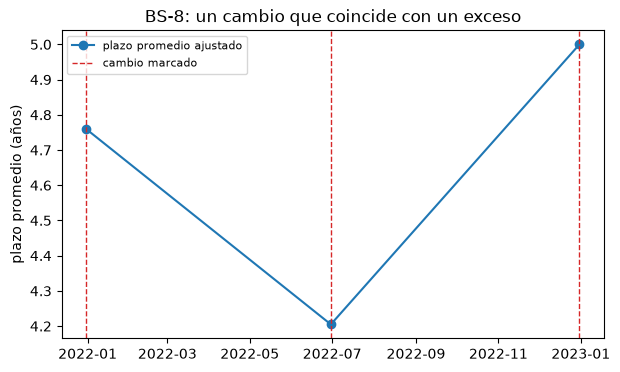

In [10]:
# Correr la prueba de exceso sobre tres parámetros de los depósitos mayoristas en las tres fechas, y un control
dates = np.array([d["outputs"]["valuation_date"] for d in docs.values()], dtype="datetime64[D]")
breach = np.array([bool(d["outputs"]["scenarios"][0]["outlier"]["breached"]) for d in docs.values()])
wholesale = [next(s for s in d["outputs"]["nmd_segments"] if s["category"] == "wholesale") for d in docs.values()]
by_date = {m["valuation_date"]: m["weighted_average_maturity_years"] for m in fit["nmd_models"]}
wam = [by_date[str(day)] for day in dates]
series = {"proporción estable pedida": [s["requested_core_share"] for s in wholesale]}
series["plazo estable pedido (a)"] = [s["requested_core_maturity_years"] for s in wholesale]
series["plazo promedio ajustado (a)"] = wam
print("fechas:", [str(x) for x in dates], "| marcas de exceso:", [NAME[bool(b)] for b in breach])
for name, values in series.items():
    run = rv_irrbb.behavioural_change_at_breach(np.array(values), dates, breach)
    print(f"{name:34s} {[round(v, 4) for v in values]}")
    print(f"    {LIGHT[run.light.value]} | fechas marcadas: {run.extras['flagged_dates']}")
control = rv_irrbb.behavioural_change_at_breach(np.array(wam), dates, np.zeros(3, dtype=bool))
print("control: el plazo ajustado sin exceso ->", LIGHT[control.light.value])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dates, wam, marker="o", color="tab:blue", label="plazo promedio ajustado")
for day in run.extras["flagged_dates"]:
    ax.axvline(np.datetime64(day), color="tab:red", linestyle="--", linewidth=1)
ax.axvline(dates[0], color="tab:red", linestyle="--", linewidth=1, label="cambio marcado")
ax.set_ylabel("plazo promedio (años)")
ax.set_title("BS-8: un cambio que coincide con un exceso")
ax.legend(fontsize=8)
plt.show()

Dos de los tres parámetros no se mueven: la proporción de los depósitos estables que pide Contraste queda en 0,6 y su plazo en 5 años, y la prueba es verde para ambos aunque el límite se incumple en todas las fechas. El plazo promedio ajustado sí se mueve, 4,7595, 4,2049 y 5,0 años, y la prueba es roja en 2022-06-30 y 2022-12-31, las fechas de las líneas de trazos; con las marcas de exceso en falso la misma serie es verde, así que la marca decide el veredicto. La figura muestra que la prueba opera sobre los parámetros versionados. No muestra que alguien haya ajustado el plazo ajustado: se reestima en cada fecha y por eso difiere por construcción.

**El límite de BS-8.** La fila roja no es un hallazgo sobre el banco. En C14 la prueba de valores atípicos del banco se supera en las tres fechas, así que la marca de incumplimiento nunca varía; el parámetro que se mueve es el plazo de la cartera replicante ajustada, que se reestima en cada fecha y por lo tanto difiere por construcción, mientras los dos parámetros que declara Contraste se mantienen fijos y no se marcan. Lo que la evidencia muestra es que la prueba separa un supuesto declarado mantenido durante un incumplimiento de una serie que se mueve mientras se incumple el límite, y que su veredicto lo decide la marca de incumplimiento; la misma serie sin incumplimiento es verde. No muestra que alguien eligiera el plazo ajustado para aliviar un incumplimiento, y el comportamiento del banco es sintético. Un rojo es una invitación al validador a preguntar quién movió el parámetro, cuándo, por qué y con qué aprobación, y si el nuevo valor lo respalda la data; las primeras respuestas están en el registro de gobierno de modelos, no en la prueba.

## Resultados

**Respuesta:** sí a ambas, con límites. Tratar los flujos en UF como pesos da un delta NII de 1.356 para la variante short-uf frente al valor del Anexo 1 de 11.067, y un delta EVE de 64.213 frente a 79.643, así que la medida del regulador no es la que da un cálculo de una sola moneda. La prueba de exceso marca el plazo promedio ajustado de los depósitos mayoristas en 2022-06-30 y 2022-12-31, mientras la proporción estable pedida (0,6) y el plazo pedido (5 años) son verdes y la misma serie ajustada sin exceso es verde: la marca de exceso decide.

- **BS-7, la separación.** Ninguna tabla de Basilea trae el peso ni la UF (21 monedas cada una), y el motor rechaza un tamaño para ellos. La tabla chilena da al peso 300/400/200 pb y a la UR 200/250/150 pb para el EVE y 300 pb para el NII, y cada moneda está en su propia curva: 0,04499 en la primera banda para el peso y 0,01205 para la UR. El piso tiene que ser el propio de la moneda: una baja de 200 pb lleva la curva UR a -0,00795 en la primera banda, y el piso en pesos de 0 actuaría en nueve bandas mientras el piso UR de -2 por ciento no actúa en ninguna.
- **BS-7, lo que pierde una sola moneda.** El delta NII es 1.356, 1.648 y 1.254 frente a 11.067, 11.213 y 11.016 en las variantes short-uf, long-uf y offset-on-off: entre 6,8 y 8,8 veces menor. El delta EVE es 64.213, 84.710 y 59.422 frente a 79.643, 93.816 y 81.173: entre 10 y 27 por ciento menor. Ninguna razón al Tier 1 cruza una línea con ninguno de los dos tratamientos en estas cuatro variantes.
- **BS-7, la compensación y el cargo.** La compensación baja el delta NII de 14.597 a 11.067 en la variante short-uf y el delta EVE de 94.721 a 81.173 en la variante offset-on-off. El cargo es 0,5586, 0,5513 y 0,5612 del delta NII en las tres variantes con una posición neta en UF de 30 por ciento del Tier 1, y 0,1560 en la de 5 por ciento.
- **BS-7, el límite.** Los pisos nunca actúan: la tasa con choque más cercana está a 20,48 pb de su piso en las cuatro variantes, así que su efecto sobre un número no se demuestra aquí. No hay una segunda implementación del Anexo 1 con la cual reconciliar; la búsqueda del dossier no encontró ninguna, lo que queda sin verificar más allá de ella. El banco es sintético, y la afirmación es regional.
- **BS-8, la discriminación.** En las cinco historias construidas la prueba da el veredicto que dice la regla: verde para un parámetro fijo durante un exceso, verde para un cambio sin exceso, verde para un cambio antes del exceso, roja para un cambio en el exceso (marcando 2022-12-31), y no evaluada para una sola fecha.
- **BS-8, el banco versionado.** La proporción estable pedida (0,6) y el plazo estable pedido (5,0 años) no cambian y la prueba es verde; el plazo promedio ajustado se mueve, 4,7595, 4,2049 y 5,0 años, y la prueba es roja en 2022-06-30 y 2022-12-31. Con las marcas de exceso en falso la misma serie es verde.
- **BS-8, el límite.** La prueba de valores atípicos se incumple en las tres fechas, así que la marca nunca varía, y el parámetro que se mueve es uno ajustado que se reestima en cada fecha, así que difiere por construcción. El rojo no es entonces un hallazgo de que alguien ajustó el plazo para aliviar un exceso; muestra que la prueba opera sobre esos parámetros y lo haría sobre un parámetro que un gerente cambió. Qué hace un validador con un rojo: pregunta quién movió el parámetro, cuándo y con qué aprobación; compara el valor nuevo con los datos que lo respaldan (el notebook 05 muestra que los pesos ajustados no son estables entre ventanas); y lee el EVE con y sin conducta en la misma fecha. El comportamiento del banco es sintético.
- **Lo que el notebook no muestra.** Una reconciliación de las cifras chilenas con una segunda implementación, el efecto de un piso sobre un número, y un caso en que un gerente cambió un supuesto declarado ante un exceso: los datos versionados no traen ninguno.

## Resumen

- BS-7: el Anexo chileno trata la UF como una moneda propia; el motor implementa sus tamaños, piso, compensación y cargo, y las variantes versionadas se recalculan desde él. Un tratamiento de una sola moneda con los mismos flujos daría un delta NII muy distinto, porque el cargo y el emparejamiento son lo que hace la medida de NII.
- BS-7 tiene límites: ninguna segunda implementación con la cual reconciliar, pisos que nunca actúan en estas curvas, un banco sintético y una afirmación regional.
- BS-8: la prueba de exceso es roja cuando un parámetro cambia en una fecha con exceso y verde en otro caso, y el veredicto lo decide la marca de exceso.
- BS-8 tiene límites: en el banco versionado toda fecha es un exceso y el parámetro que se mueve es uno ajustado, así que el rojo muestra que la prueba opera, no que el banco hiciera lo que encontró la revisión del banco quebrado.
- Ambas afirmaciones se declaran en el SDD solo hasta donde llega esta evidencia.

**Qué probar a continuación.** Cambia las marcas de exceso de las historias construidas y anota qué veredicto sigue a qué regla. Después lee las afirmaciones de la sección `## Beyond the state of the art` del SDD frente a este notebook.

## Referencias

- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1 (la UR, los tamaños, los pisos, la compensación y el cargo). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 (los tamaños de choque) y SRP31.129. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- CMF, Informe del Desempeño del Sistema Bancario y Cooperativas, agosto de 2026. https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 03 (Chile, sección F.2) y dossier 05 (sección D.7) de la investigación de Contraste; la sección `## Beyond the state of the art` del SDD.